<a href="https://colab.research.google.com/github/Richwalter/COU07506-labs/blob/main/Week_3_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 3.1 — Convolution from the Definition
We will define the manual convolution function `conv(x, h)` and verify its correctness against NumPy's built-in `np.convolve` with the test input.

In [3]:
import numpy as np

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

# Verification
x_test = [1, 2, 3, 1]
h_test = [1, 1, 1]

custom_conv_result = conv(x_test, h_test)
numpy_conv_result = np.convolve(x_test, h_test)

print("Custom conv result:", custom_conv_result)
print("NumPy convolve result:", numpy_conv_result)

Custom conv result: [1. 3. 6. 6. 4. 1.]
NumPy convolve result: [1 3 6 6 4 1]


### Performance Comparison
Now we will measure and compare the execution time of our custom implementation versus `np.convolve` using two random signals of length 2,000.

In [4]:
import time

# Generate two random sequences of length 2000
np.random.seed(42)
seq1 = np.random.randn(2000)
seq2 = np.random.randn(2000)

# Time the custom convolution
t_start = time.perf_counter()
res_custom = conv(seq1, seq2)
t_end = time.perf_counter()
time_custom = t_end - t_start

# Time NumPy's convolution
t_start = time.perf_counter()
res_numpy = np.convolve(seq1, seq2)
t_end = time.perf_counter()
time_numpy = t_end - t_start

print(f"Time taken by custom conv(): {time_custom:.6f} seconds")
print(f"Time taken by np.convolve(): {time_numpy:.6f} seconds")
print(f"Speedup factor: {time_custom / time_numpy:.1f}x")

Time taken by custom conv(): 2.010456 seconds
Time taken by np.convolve(): 0.000678 seconds
Speedup factor: 2966.1x


### Task 3.2 — Smoothing a Noisy Signal by Convolution

We will create a noisy sinusoidal signal $x(n) = \sin(2\pi n/50) + 0.5w(n)$ for $0 \le n < 300$, where $w(n)$ is zero-mean Gaussian white noise of unit variance. Then, we will filter this signal using three moving average filters of length $M = 3, 9, \text{ and } 25$ using `np.convolve(..., mode='same')` and plot the comparative results.

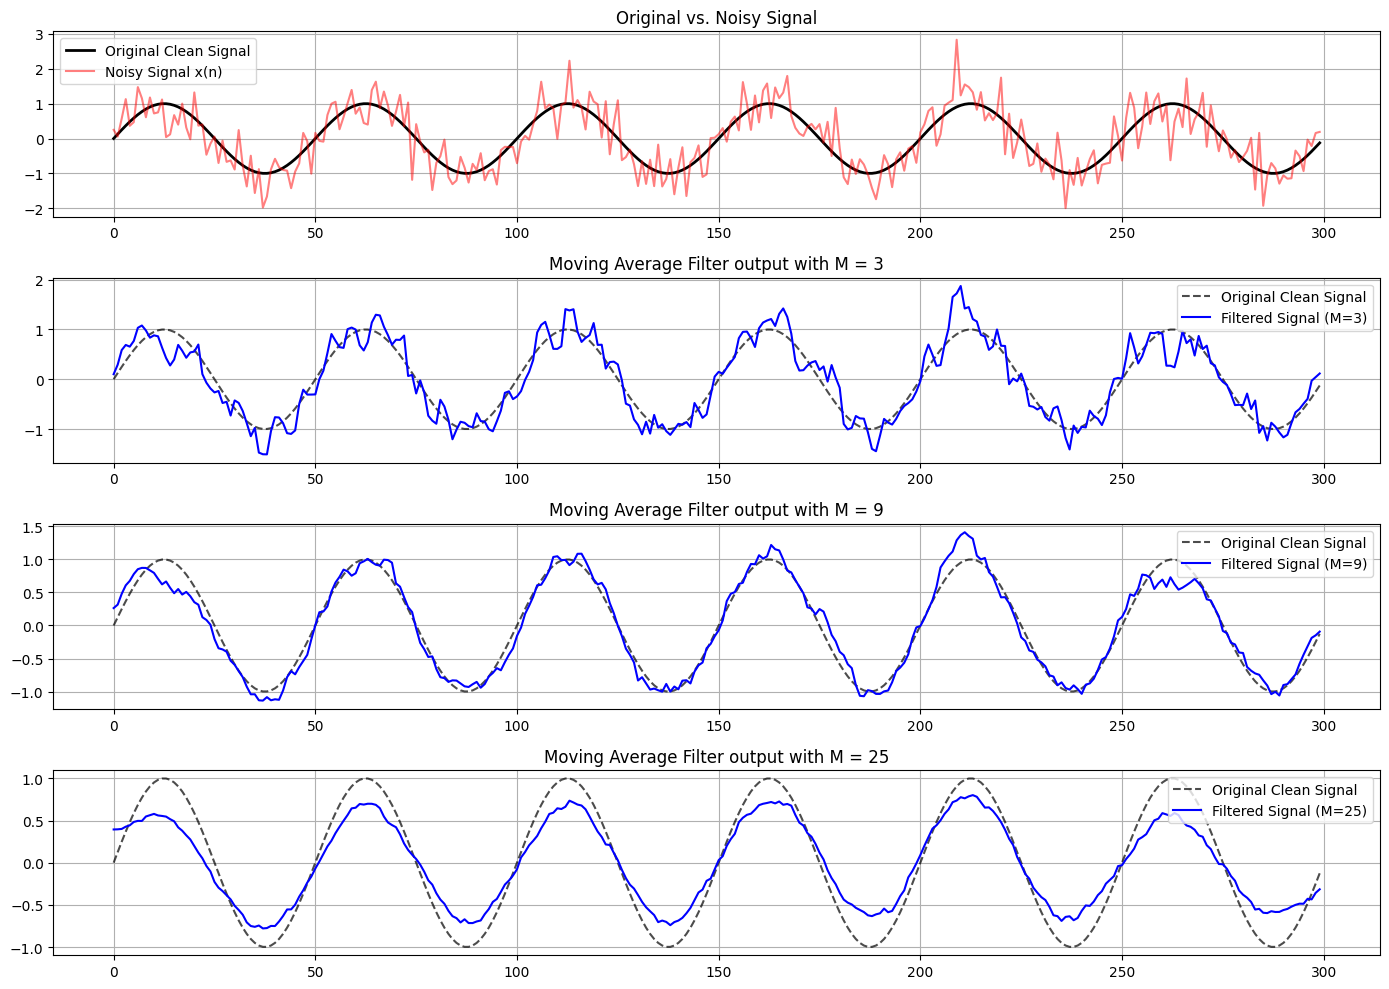

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Generate the noiseless signal
n = np.arange(300)
signal = np.sin(2 * np.pi * n / 50)

# Generate noise and noisy signal x(n)
np.random.seed(42)
w = np.random.randn(300)
x = signal + 0.5 * w

# Define moving-average impulse responses h(n)
M_values = [3, 9, 25]
outputs = {}

for M in M_values:
    h = np.ones(M) / M
    # Using mode='same' to ensure the output length matches the input length
    outputs[M] = np.convolve(x, h, mode='same')

# Plotting the results
plt.figure(figsize=(14, 10))

# Original & Noisy Signals
plt.subplot(4, 1, 1)
plt.plot(n, signal, 'k', label='Original Clean Signal', linewidth=2)
plt.plot(n, x, 'r', alpha=0.5, label='Noisy Signal x(n)')
plt.title('Original vs. Noisy Signal')
plt.grid(True)
plt.legend()

# M = 3, 9, 25 comparisons
for idx, M in enumerate(M_values, start=2):
    plt.subplot(4, 1, idx)
    plt.plot(n, signal, 'k--', label='Original Clean Signal', alpha=0.7)
    plt.plot(n, outputs[M], 'b', label=f'Filtered Signal (M={M})', linewidth=1.5)
    plt.title(f'Moving Average Filter output with M = {M}')
    plt.grid(True)
    plt.legend()

plt.tight_layout()
plt.show()

### Task 3.3 — Testing Linearity and Time-Invariance Numerically
We will define the three systems:
1. Quadratic system: $T\{x(n)\} = x^2(n)$
2. Time-varying scaling system: $T\{x(n)\} = n \cdot x(n)$
3. 3-point moving average filter: $T\{x(n)\} = \frac{1}{3}\sum_{k=0}^{2} x(n-k)$

We will test their properties numerically using random signals.

In [7]:
import numpy as np

rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0

systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

for name, T in systems.items():
    # Linearity test: T(a*x1 + b*x2) == a*T(x1) + b*T(x2)
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))

    # Delay tests (shift by 5 samples)
    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)
    # Cast linear to string to safely use string formatting
    print(f"{name:15s} linear={str(linear):5s}  time-invariant={tinv}")

x^2             linear=False  time-invariant=True
n x(n)          linear=True   time-invariant=False
moving average  linear=True   time-invariant=True


### Theoretical Explanation of the Results

#### 1. System $y(n) = x^2(n)$ (Quadratic)
* **Linearity (False)**: A linear system must satisfy homogeneity and additivity.
  $$T\{a x_1(n) + b x_2(n)\} = (a x_1(n) + b x_2(n))^2 = a^2 x_1^2(n) + 2ab x_1(n)x_2(n) + b^2 x_2^2(n)$$
  which is not equal to $a T\{x_1(n)\} + b T\{x_2(n)\} = a x_1^2(n) + b x_2^2(n)$. Therefore, it is **non-linear**.
* **Time-Invariance (True)**: If the input is delayed by $k$ samples ($x_d(n) = x(n-k)$), the output becomes:
  $$T\{x(n-k)\} = x^2(n-k) = y(n-k)$$
  Because shifting the input by $k$ results in an identical shift of $k$ in the output, the system is **time-invariant**.

#### 2. System $y(n) = n \cdot x(n)$ (Time-varying Gain)
* **Linearity (True)**:
  $$T\{a x_1(n) + b x_2(n)\} = n(a x_1(n) + b x_2(n)) = a(n x_1(n)) + b(n x_2(n)) = a T\{x_1(n)\} + b T\{x_2(n)\}$$
  Since it satisfies superposition, the system is **linear**.
* **Time-Invariance (False)**: If we delay the input by $k$ samples ($x_d(n) = x(n-k)$), the output is:
  $$T\{x_d(n)\} = n \cdot x(n-k)$$
  However, the delayed version of the original output $y(n) = n x(n)$ is:
  $$y(n-k) = (n-k) x(n-k)$$
  Since $n x(n-k) \neq (n-k)x(n-k)$ for $k \neq 0$, the system is **time-varying (not time-invariant)**.

#### 3. System $y(n) = \text{moving average}$ (LTI Convolution)
* **Linearity (True)**: Convolution is a linear mathematical operator. Thus, any system described solely by convolution with a fixed impulse response $h(n)$ is inherently **linear**.
* **Time-Invariance (True)**: Convolution with a fixed impulse response $h(n)$ is inherently a **time-invariant** operation. Delaying the input signal simply shifts the output signal by the same amount.

### Task 3.4 — Finding a Hidden Delay with Cross-Correlation
We will transmit a random signal $x(n)$ which is delayed by 37 samples to form $y(n)$ at a sample rate $f_s = 1000\text{ Hz}$. We will add Gaussian noise with standard deviation values $\sigma = 0.5, 1, 2, \text{ and } 4$ to the received signal, plot the cross-correlation functions to find the estimated delay, and analyze the distance conversion.

<>:30: SyntaxWarning: invalid escape sequence '\('
<>:30: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_2649/415671831.py:30: SyntaxWarning: invalid escape sequence '\('
  plt.title(f'Noise Std Dev \(\sigma\) = {sigma} (Est: {est_delay} samples)')


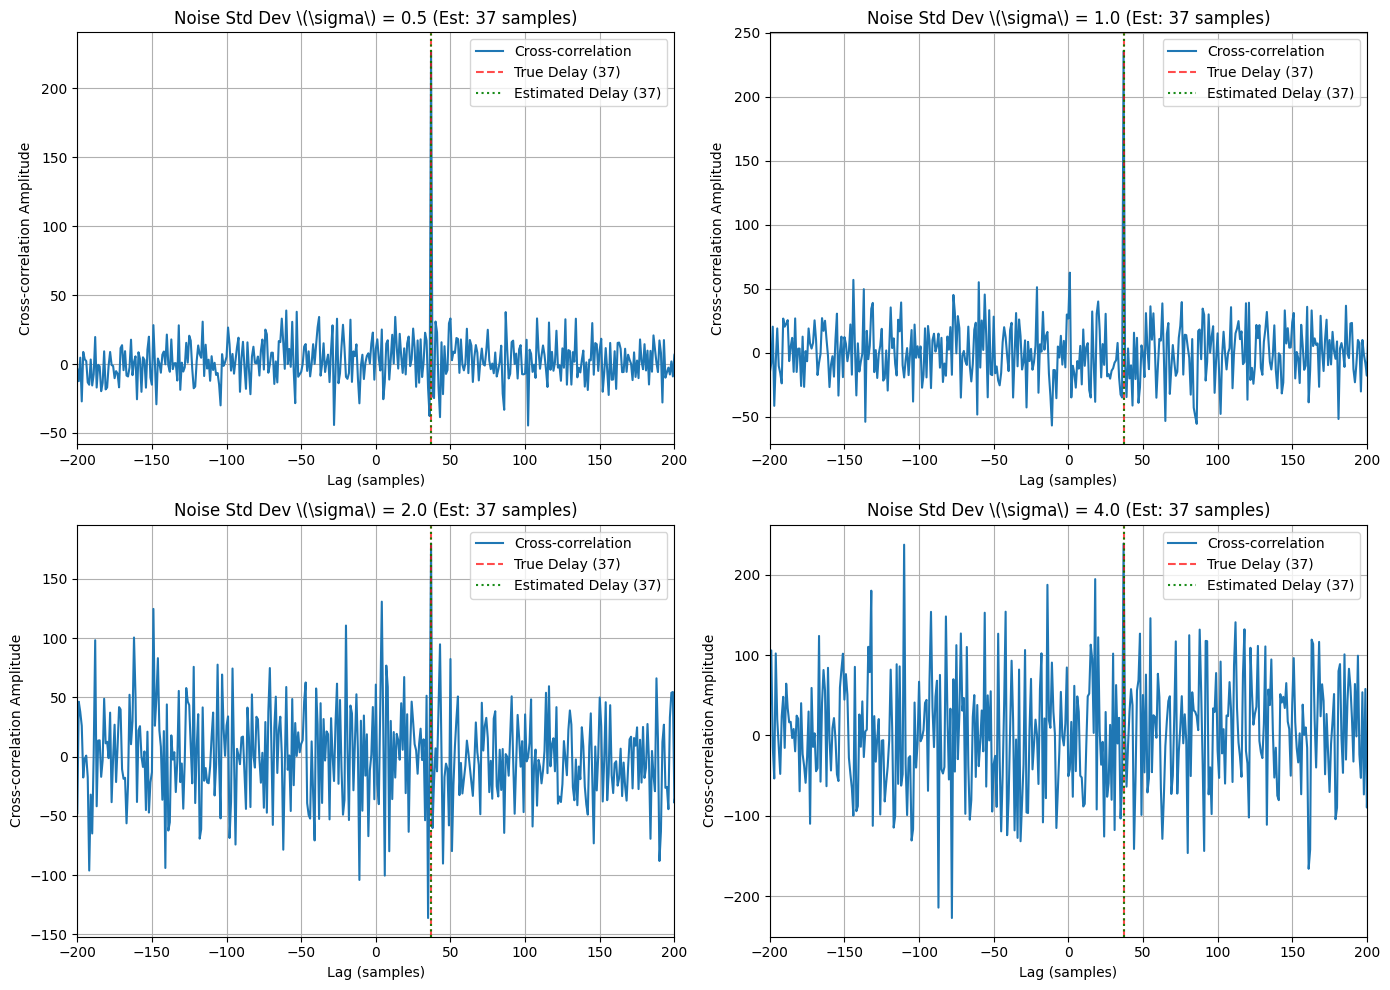

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)  # Transmitted signal
true_delay = 37

# We will test noise standard deviations: 0.5 (original), 1.0, 2.0, and 4.0
noise_stds = [0.5, 1.0, 2.0, 4.0]

plt.figure(figsize=(14, 10))

for i, sigma in enumerate(noise_stds):
    # Received signal with noise standard deviation = sigma
    y = np.concatenate([np.zeros(true_delay), 0.6 * x])[:500] + sigma * rng.standard_normal(500)

    # Cross-correlation
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")

    est_delay = lags[np.argmax(r)]

    plt.subplot(2, 2, i+1)
    plt.plot(lags, r, label='Cross-correlation')
    plt.axvline(true_delay, color='r', linestyle='--', alpha=0.7, label=f'True Delay ({true_delay})')
    plt.axvline(est_delay, color='g', linestyle=':', alpha=0.9, label=f'Estimated Delay ({est_delay})')
    plt.xlim(-200, 200)
    plt.title(fr'Noise Std Dev $\sigma$ = {sigma} (Est: {est_delay} samples)')
    plt.xlabel('Lag (samples)')
    plt.ylabel('Cross-correlation Amplitude')
    plt.grid(True)
    plt.legend()

plt.tight_layout()
plt.show()

### Distance Calculation
Given a sound pulse traveling at $v = 343 \text{ m/s}$ and a sampling rate of $f_s = 1000 \text{ Hz}$:
- Each sample delay corresponds to a time difference of $\Delta t = \frac{1}{f_s} = \frac{1}{1000} = 0.001 \text{ s}$ (1 ms).
- The estimated delay of 37 samples corresponds to:
  $$\text{Distance} = v \times \Delta t \times \text{delay} = 343 \text{ m/s} \times 0.001 \text{ s/sample} \times 37 \text{ samples}$$


In [9]:
# Physical Distance Calculation
speed_of_sound = 343  # m/s
sample_period = 1 / fs  # seconds
estimated_delay = 37

distance = speed_of_sound * sample_period * estimated_delay
print(f"Estimated delay: {estimated_delay} samples")
print(f"Time delay: {estimated_delay * sample_period * 1000:.1f} ms")
print(f"Calculated physical distance: {distance:.3f} meters")

Estimated delay: 37 samples
Time delay: 37.0 ms
Calculated physical distance: 12.691 meters


### Task 3.5 — Difference Equation

We consider the system described by the difference equation:
$$y(n) - \frac{3}{4}y(n-1) + \frac{1}{8}y(n-2) = x(n) + x(n-1)$$

This is an Infinite Impulse Response (IIR) filter with coefficients:
- Feedback coefficients (denominator): $a = [1, -0.75, 0.125]$
- Feedforward coefficients (numerator): $b = [1, 1]$

In [10]:
import numpy as np
from scipy import signal

# Number of samples to compute
N = 10
n = np.arange(N)

# 1. Direct recursion using a for loop
# Input: impulse delta(n)
x_impulse = np.zeros(N)
x_impulse[0] = 1.0

y_rec = np.zeros(N)
for i in range(N):
    # y(n) = 3/4 * y(n-1) - 1/8 * y(n-2) + x(n) + x(n-1)
    val = 0.0
    if i - 1 >= 0:
        val += 0.75 * y_rec[i-1] + x_impulse[i-1]
    if i - 2 >= 0:
        val -= 0.125 * y_rec[i-2]
    val += x_impulse[i]
    y_rec[i] = val

# 2. Computation using scipy.signal.lfilter
b = [1, 1]
a = [1, -0.75, 0.125]
y_lfilter = signal.lfilter(b, a, x_impulse)

# 3. Analytical closed-form solution: h(n) = 6*(0.5)^n - 5*(0.25)^n
y_analytical = 6 * (0.5)**n - 5 * (0.25)**n

# Comparison printout
print(f"{'n':<3} | {'Recursion h(n)':<15} | {'lfilter h(n)':<15} | {'Analytical h(n)':<15}")
print("-" * 58)
for idx in range(N):
    print(f"{idx:<3} | {y_rec[idx]:<15.6f} | {y_lfilter[idx]:<15.6f} | {y_analytical[idx]:<15.6f}")

n   | Recursion h(n)  | lfilter h(n)    | Analytical h(n)
----------------------------------------------------------
0   | 1.000000        | 1.000000        | 1.000000       
1   | 1.750000        | 1.750000        | 1.750000       
2   | 1.187500        | 1.187500        | 1.187500       
3   | 0.671875        | 0.671875        | 0.671875       
4   | 0.355469        | 0.355469        | 0.355469       
5   | 0.182617        | 0.182617        | 0.182617       
6   | 0.092529        | 0.092529        | 0.092529       
7   | 0.046570        | 0.046570        | 0.046570       
8   | 0.023361        | 0.023361        | 0.023361       
9   | 0.011700        | 0.011700        | 0.011700       


In [11]:
# Compute the step response (input is a unit step u(n))
x_step = np.ones(50)  # Extended length to ensure convergence to steady-state
y_step = signal.lfilter(b, a, x_step)

# Final value of step response
final_val = y_step[-1]

# Analytical value at DC (H(1))
H_1 = sum(b) / sum(a)

print(f"Final value of simulated step response: {final_val:.6f}")
print(f"Analytical value H(1) = sum(b)/sum(a): {H_1:.6f}")

Final value of simulated step response: 5.333333
Analytical value H(1) = sum(b)/sum(a): 5.333333


### Frequency Response of the IIR Filter
We can analyze the frequency characteristics of our second-order IIR system by computing its frequency response $H(e^{j\omega})$ using `scipy.signal.freqz`. This will show how different frequencies are scaled (magnitude response) and delayed (phase response) by the filter.

<>:20: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_2649/3910482481.py:20: SyntaxWarning: invalid escape sequence '\p'
  ax1.set_xlabel('Normalized Frequency ($\times \pi$ rad/sample)')


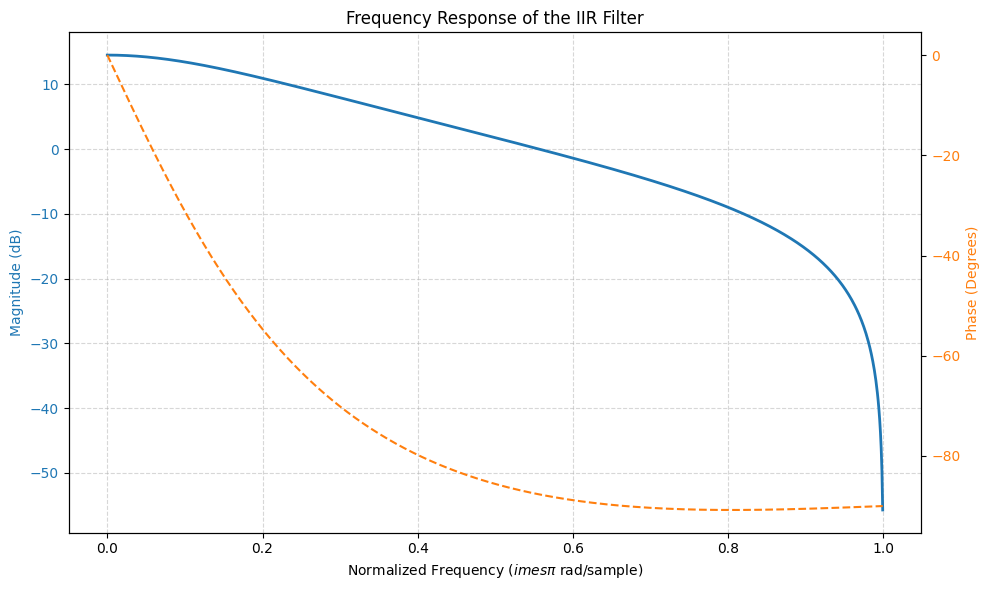

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Filter coefficients from Task 3.5
b = [1, 1]
a = [1, -0.75, 0.125]

# Compute frequency response
w, h = signal.freqz(b, a, worN=1024)

# Frequency axis normalized to [0, pi] or normalized frequency (cycles/sample)
normalized_freq = w / np.pi

# Plot Magnitude and Phase Response
fig, ax1 = plt.subplots(figsize=(10, 6))

# Magnitude Plot (dB)
color = 'tab:blue'
ax1.set_xlabel('Normalized Frequency ($\times \pi$ rad/sample)')
ax1.set_ylabel('Magnitude (dB)', color=color)
ax1.plot(normalized_freq, 20 * np.log10(np.abs(h)), color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, which='both', linestyle='--', alpha=0.5)
ax1.set_title('Frequency Response of the IIR Filter')

# Phase Plot (Degrees)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Phase (Degrees)', color=color)
ax2.plot(normalized_freq, np.angle(h, deg=True), color=color, linestyle='--', linewidth=1.5)
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()
plt.show()

        ANSWERS TO Analysis questions

1. np.convolve is implemented in optimized compiled code (C/NumPy internals), while a double loop executes slowly in Python. Therefore, np.convolve performs the same calculations much more efficiently.

2. For direct convolution:
       Multiplications=L×M

    where LLL and MMM are the lengths of the two sequences.

3. A system is LTI if it is linear and time-invariant.

Yes. You can determine this directly from the system equations by checking linearity and time invariance, without running the code.

4. Locating leaks in water distribution pipes.
Radar and aircraft tracking at airports (e.g., Julius Nyerere International Airport).